In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:

url = "https://raw.githubusercontent.com/bibanaksu/PM25-Forecasting-GRU/main/Files/combined_gee_pm25_clean.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)


Dataset shape: (40983, 15)


In [ ]:
print(df.head().to_string())


         date         datetime_utc  id   latitude  longitude  temperature_celsius  pressure_mb    wind_u    wind_v  NO2  CO  O3     AOD       pm25              sensor_name
0  2016-11-25  2016-11-25 00:00:00   1  38.788056  -0.697222             6.493180   946.288660  0.230240  0.735303  NaN NaN NaN  0.1110   2.750000                ONTINYENT
1  2016-11-25  2016-11-25 00:00:00  36  39.945278  -0.056389             9.251236   993.626994  0.783218 -0.592618  NaN NaN NaN  0.0220  11.666667  ALMASSORA-C. P. OCHANDO
2  2016-11-30  2016-11-30 00:00:00  35  40.051944  -0.189722            10.044782   981.911432 -2.211047 -1.568971  NaN NaN NaN  0.2380   2.400000                   ALCORA
3  2016-11-30  2016-11-30 00:00:00  37  40.062222   0.072778            12.299584  1008.794766 -3.236886 -2.804465  NaN NaN NaN  0.2480   2.600000               BENICASSIM
4  2016-12-02  2016-12-02 00:00:00   1  38.788056  -0.697222             9.350630   953.114180  0.953454  0.293060  NaN NaN NaN  0.0755   2.

In [18]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40983 entries, 0 to 40982
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 40983 non-null  object 
 1   datetime_utc         40983 non-null  object 
 2   id                   40983 non-null  int64  
 3   latitude             40983 non-null  float64
 4   longitude            40983 non-null  float64
 5   temperature_celsius  40983 non-null  float64
 6   pressure_mb          40983 non-null  float64
 7   wind_u               40983 non-null  float64
 8   wind_v               40983 non-null  float64
 9   NO2                  38576 non-null  float64
 10  CO                   38576 non-null  float64
 11  O3                   38535 non-null  float64
 12  AOD                  40983 non-null  float64
 13  pm25                 40983 non-null  float64
 14  sensor_name          40983 non-null  object 
dtypes: float64(11),

In [19]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print(missing)

                     Missing Values  Missing Percentage
date                              0                0.00
datetime_utc                      0                0.00
id                                0                0.00
latitude                          0                0.00
longitude                         0                0.00
temperature_celsius               0                0.00
pressure_mb                       0                0.00
wind_u                            0                0.00
wind_v                            0                0.00
NO2                            2407                5.87
CO                             2407                5.87
O3                             2448                5.97
AOD                               0                0.00
pm25                              0                0.00
sensor_name                       0                0.00


In [20]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,40983.0,52.73,35.03,0.00,21.00,50.00,90.00,109.00
latitude,40983.0,39.03,2.23,36.13,36.84,39.45,40.05,43.53
longitude,40983.0,-0.47,3.83,-5.66,-3.61,-0.41,1.15,9.14
temperature_celsius,40983.0,18.27,6.39,-1.28,12.97,18.49,23.79,34.87
pressure_mb,40983.0,993.82,17.18,930.32,987.99,997.73,1005.37,1033.66
wind_u,40983.0,0.34,2.53,-11.10,-0.98,0.21,1.68,9.66
wind_v,40983.0,-0.18,1.39,-10.86,-0.73,0.04,0.66,8.49
NO2,38576.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
CO,38576.0,0.03,0.00,0.01,0.03,0.03,0.03,0.10
O3,38535.0,0.14,0.01,0.10,0.13,0.14,0.15,0.23


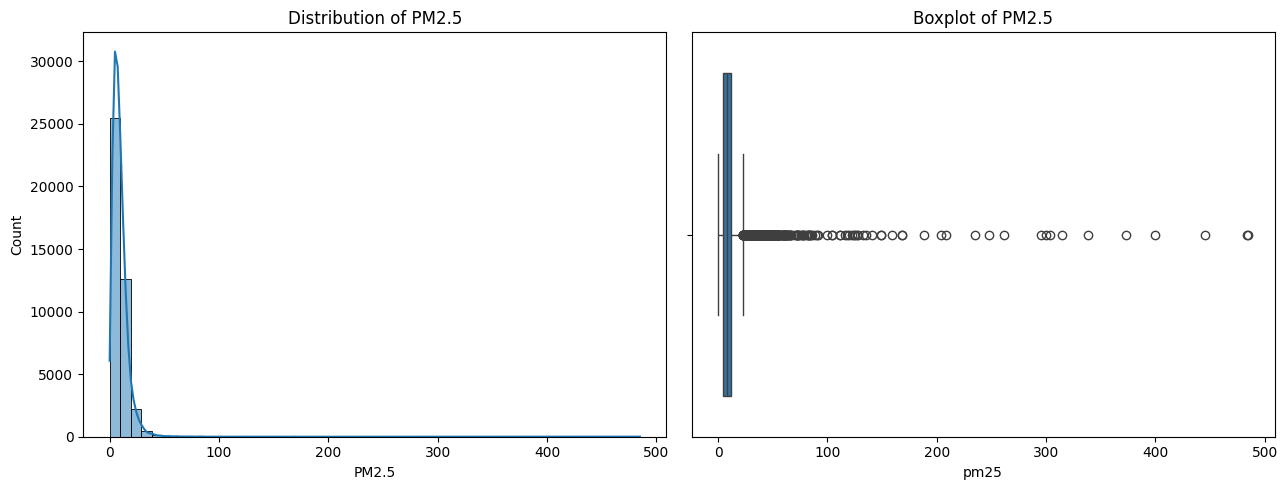

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["pm25"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of PM2.5")
axes[0].set_xlabel("PM2.5")

sns.boxplot(x=df["pm25"], ax=axes[1])
axes[1].set_title("Boxplot of PM2.5")

plt.tight_layout()
plt.show()

In [22]:
q1 = df["pm25"].quantile(0.25)
q3 = df["pm25"].quantile(0.75)

iqr = q3 - q1
upper = q3 + 1.5 * iqr

outliers = df[df["pm25"] > upper]

print("Skewness:", round(df["pm25"].skew(), 2))
print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("Upper bound:", round(upper, 2))
print("Number of outliers:", len(outliers))

Skewness: 17.83
Q1: 4.67
Q3: 12.09
Upper bound: 23.21
Number of outliers: 1613


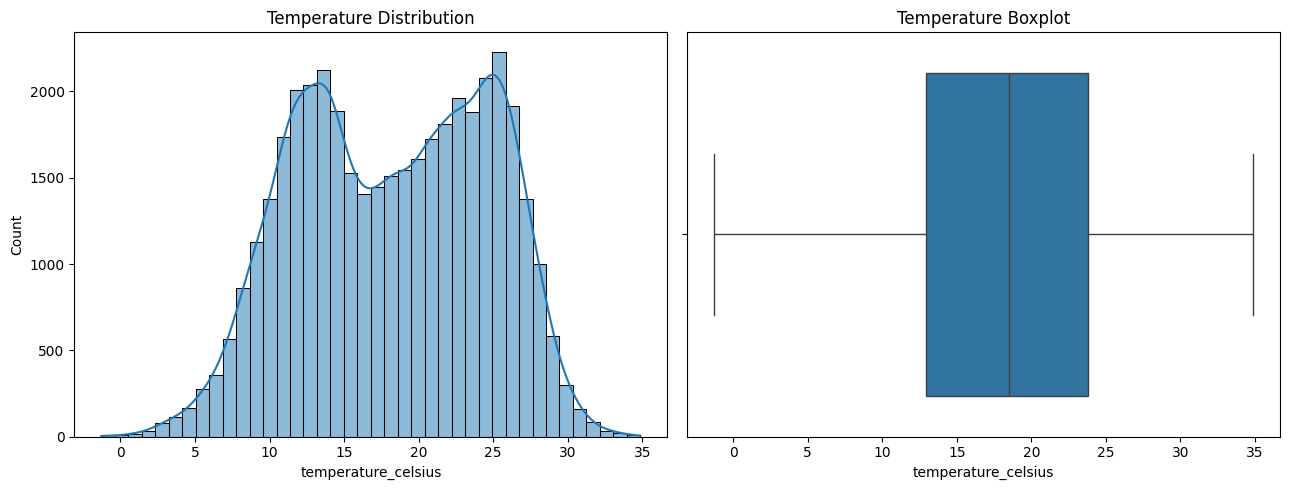

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["temperature_celsius"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Temperature Distribution")

sns.boxplot(x=df["temperature_celsius"], ax=axes[1])
axes[1].set_title("Temperature Boxplot")

plt.tight_layout()
plt.show()

In [24]:
q1 = df["temperature_celsius"].quantile(0.25)
q3 = df["temperature_celsius"].quantile(0.75)

iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

outliers = df[
    (df["temperature_celsius"] < lower) |
    (df["temperature_celsius"] > upper)
]

print("Skewness:", round(df["temperature_celsius"].skew(), 2))
print("Lower bound:", round(lower, 2))
print("Upper bound:", round(upper, 2))
print("Number of outliers:", len(outliers))

Skewness: -0.1
Lower bound: -3.27
Upper bound: 40.02
Number of outliers: 0


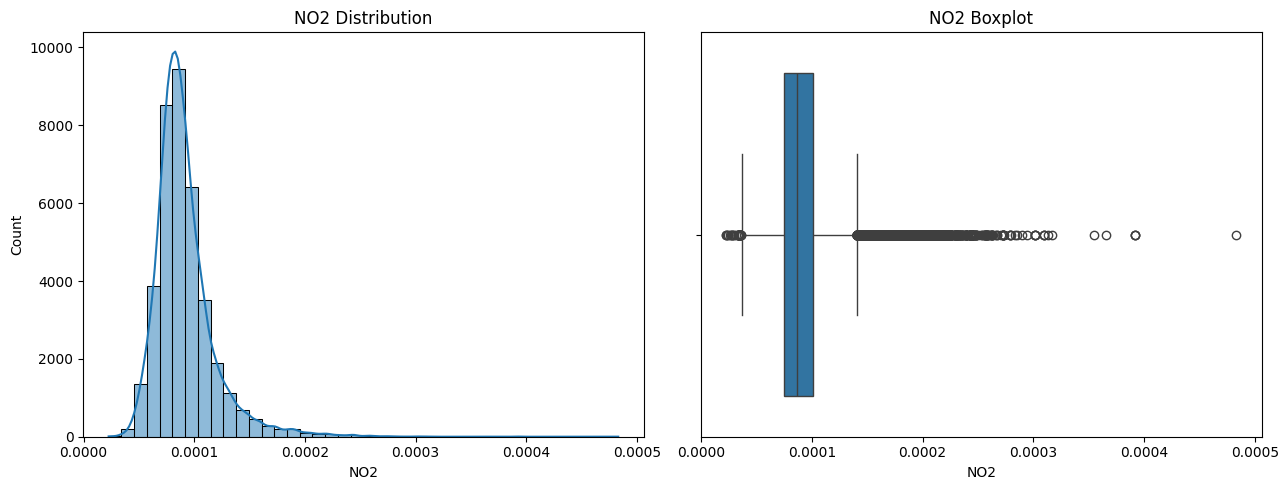

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["NO2"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("NO2 Distribution")

sns.boxplot(x=df["NO2"].dropna(), ax=axes[1])
axes[1].set_title("NO2 Boxplot")

plt.tight_layout()
plt.show()

In [28]:
col = "NO2"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.8f}")
print("Upper bound:", f"{upper:.8f}")
print("Number of outliers:", len(outliers))

Skewness: 2.12
Lower bound: 0.00003596
Upper bound: 0.00014038
Number of outliers: 2061


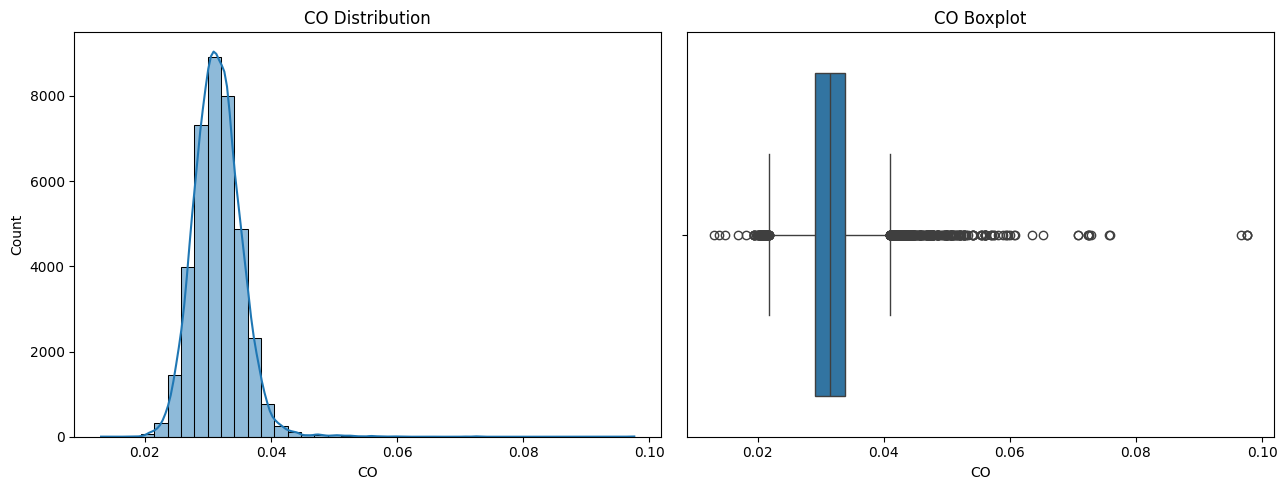

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["CO"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("CO Distribution")

sns.boxplot(x=df["CO"].dropna(), ax=axes[1])
axes[1].set_title("CO Boxplot")

plt.tight_layout()
plt.show()

In [30]:
col = "CO"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 1.4
Lower bound: 0.021862
Upper bound: 0.041005
Number of outliers: 572


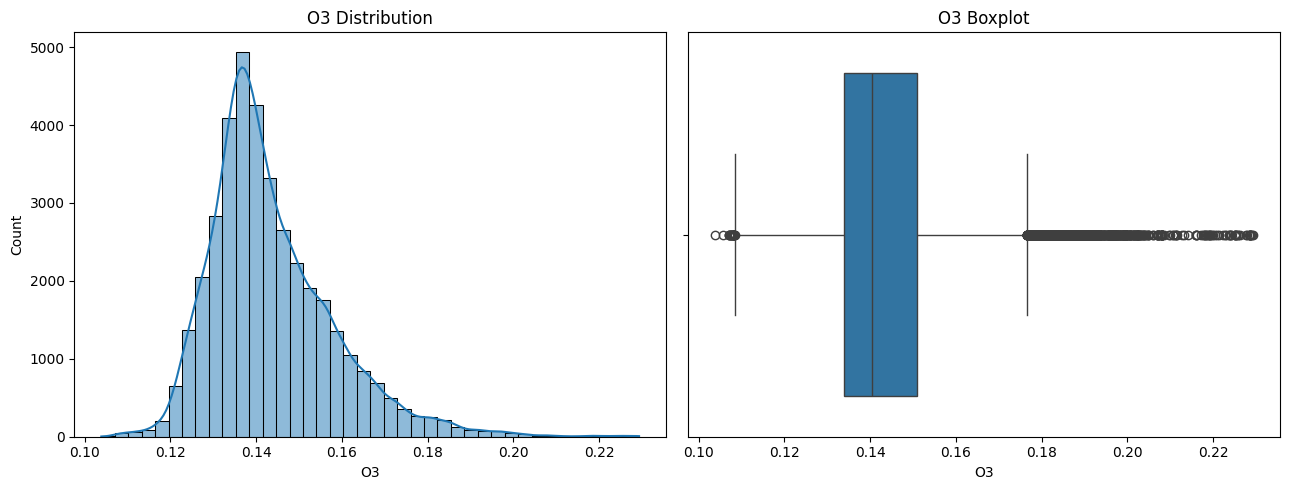

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["O3"].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title("O3 Distribution")

sns.boxplot(x=df["O3"].dropna(), ax=axes[1])
axes[1].set_title("O3 Boxplot")

plt.tight_layout()
plt.show()

In [32]:
col = "O3"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 1.15
Lower bound: 0.108476
Upper bound: 0.176592
Number of outliers: 1219


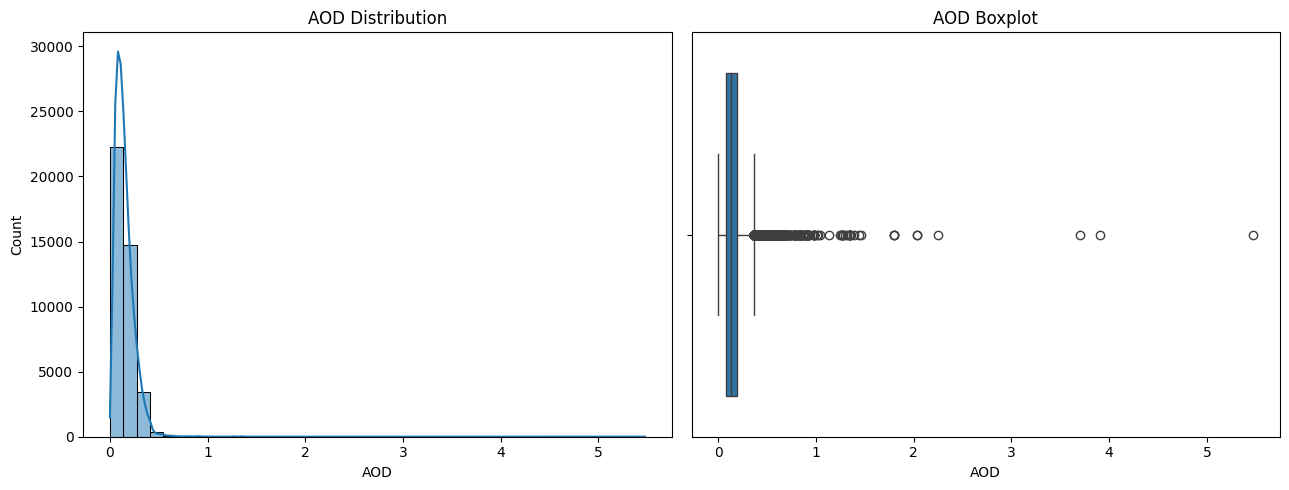

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["AOD"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("AOD Distribution")

sns.boxplot(x=df["AOD"], ax=axes[1])
axes[1].set_title("AOD Boxplot")

plt.tight_layout()
plt.show()

In [34]:
col = "AOD"

q1 = df[col].quantile(0.25)
q3 = df[col].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = df[(df[col] < lower) | (df[col] > upper)]

print("Skewness:", round(df[col].skew(), 2))
print("Lower bound:", f"{lower:.6f}")
print("Upper bound:", f"{upper:.6f}")
print("Number of outliers:", len(outliers))

Skewness: 7.61
Lower bound: -0.091000
Upper bound: 0.365000
Number of outliers: 1114


In [35]:
numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")

print("PEARSON CORRELATION")
print(pearson_corr.round(2).to_string())

print("\nSPEARMAN CORRELATION")
print(spearman_corr.round(2).to_string())

PEARSON CORRELATION
                     latitude  longitude  temperature_celsius  pressure_mb  wind_u  wind_v   NO2    CO    O3   AOD  pm25
latitude                 1.00       0.81                -0.14         0.07    0.12   -0.20  0.17  0.16  0.14 -0.03 -0.05
longitude                0.81       1.00                -0.10         0.07    0.13   -0.21  0.02  0.17  0.12 -0.00 -0.02
temperature_celsius     -0.14      -0.10                 1.00        -0.06   -0.18    0.34 -0.06 -0.13 -0.32  0.33 -0.01
pressure_mb              0.07       0.07                -0.06         1.00   -0.09   -0.04  0.17  0.20 -0.03  0.02  0.11
wind_u                   0.12       0.13                -0.18        -0.09    1.00   -0.22 -0.09  0.03  0.16 -0.25 -0.08
wind_v                  -0.20      -0.21                 0.34        -0.04   -0.22    1.00  0.11 -0.07 -0.12  0.16  0.06
NO2                      0.17       0.02                -0.06         0.17   -0.09    0.11  1.00  0.10 -0.09 -0.06  0.16
CO          

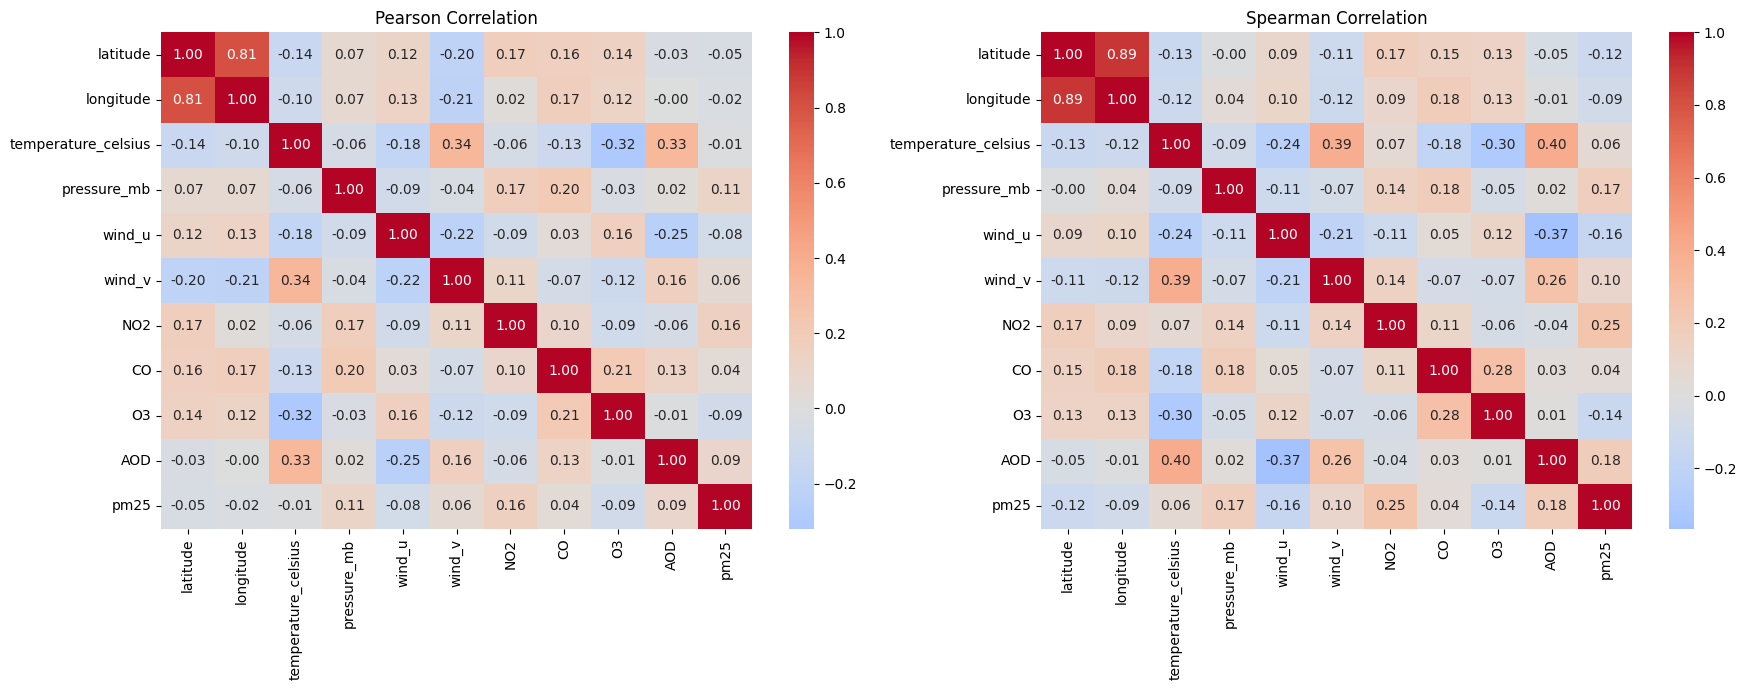

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(pearson_corr, annot=True, cmap="coolwarm",
            center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Pearson Correlation")

sns.heatmap(spearman_corr, annot=True, cmap="coolwarm",
            center=0, fmt=".2f", ax=axes[1])
axes[1].set_title("Spearman Correlation")

plt.tight_layout()
plt.show()

In [37]:
station_pm25 = df.groupby("sensor_name")["pm25"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

print(station_pm25.to_string())

                                      count   mean  median   min     max    std
sensor_name                                                                    
AIX CENTRE ECOLE ART                    458   7.14    5.76  0.90   33.60   4.82
AIX ROY RENE                            198  10.01    9.12  2.70   30.66   5.01
ALBALAT DELS TARONGERS                  798   3.74    2.50  0.04   32.62   4.01
ALCANTARILLA                            268  11.11    9.44  1.92   47.41   7.07
ALCORA                                  761   7.28    5.53  0.12  303.50  12.15
ALGAR DE PALÀNCIA                       771   4.65    3.76  0.04   31.35   3.98
ALMASSORA-C. P. OCHANDO                 739   7.28    4.92  0.12  125.25   8.74
ALUMBRES                                197   9.34    7.64  2.01   62.76   6.25
Albors - Valencia                        57  14.27    7.35  0.30   54.05  14.32
Armilla Center                          184   8.84    4.75  0.06   46.31  10.03
Avinguda Meridiana, Sagerra             

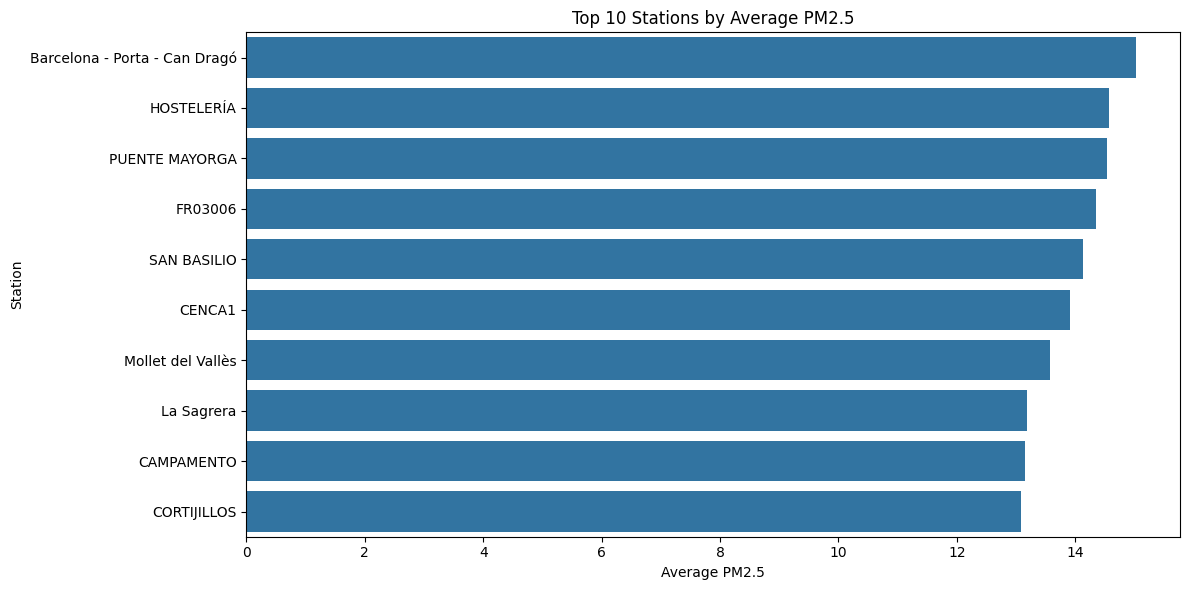

In [39]:
reliable_stations = station_pm25[station_pm25["count"] >= 100]

top10 = reliable_stations.sort_values(
    by="mean", ascending=False
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top10["mean"], y=top10.index)

plt.title("Top 10 Stations by Average PM2.5")
plt.xlabel("Average PM2.5")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

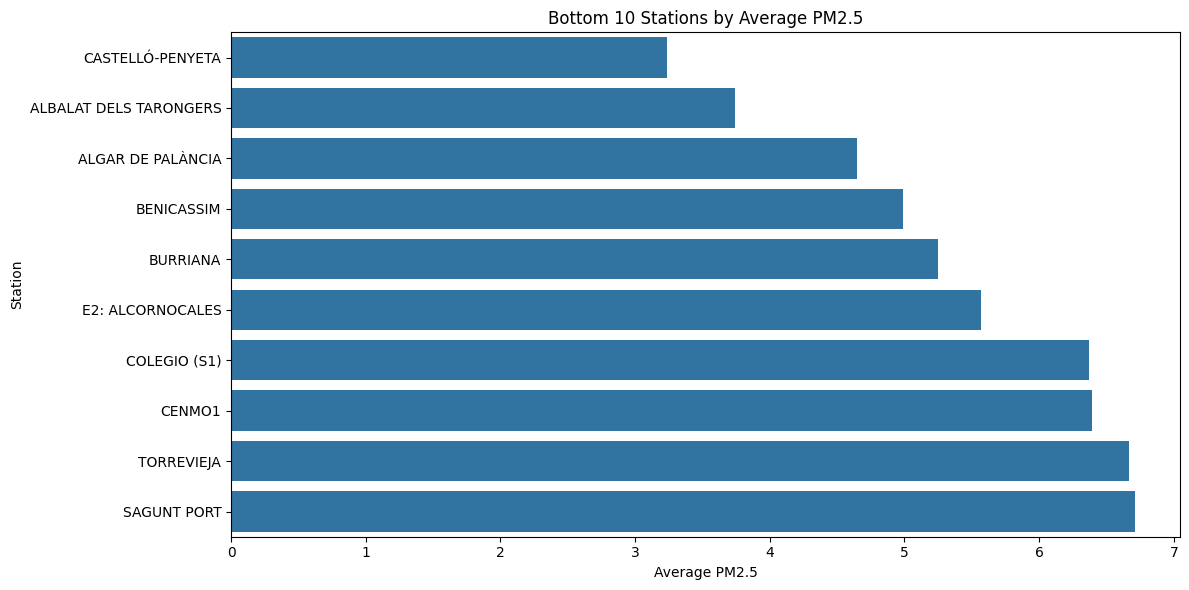

In [40]:
bottom10 = reliable_stations.sort_values(
    by="mean", ascending=True
).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=bottom10["mean"], y=bottom10.index)

plt.title("Bottom 10 Stations by Average PM2.5")
plt.xlabel("Average PM2.5")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

In [41]:
dates = pd.to_datetime(df["date"])

df["season"] = dates.dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

season_pm25 = df.groupby("season")["pm25"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

print(season_pm25.to_string())

        count   mean  median   min     max    std
season                                           
Autumn  10003   9.08    7.47  0.01  484.98  12.02
Spring   9276   8.25    6.83  0.01  303.50   7.40
Summer  12766   9.59    8.50  0.02  234.88   7.21
Winter   8938  10.94    8.77  0.03  399.40  11.72


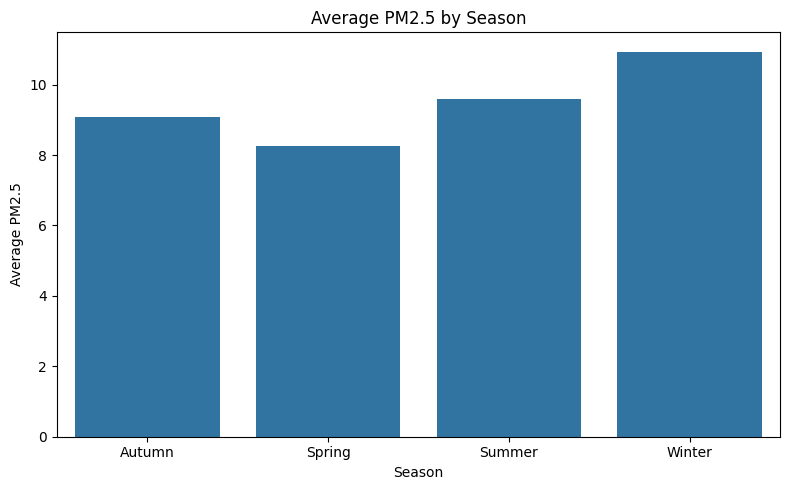

In [42]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=season_pm25.reset_index(),
    x="season",
    y="mean"
)

plt.title("Average PM2.5 by Season")
plt.xlabel("Season")
plt.ylabel("Average PM2.5")
plt.tight_layout()
plt.show()

In [43]:
total = df["pm25"].count()

above_25 = (df["pm25"] > 25).sum()
above_50 = (df["pm25"] > 50).sum()

print("Total observations:", total)

print("PM2.5 > 25:")
print("Count:", above_25)
print("Percentage:", round(above_25 / total * 100, 2), "%")

print("\nPM2.5 > 50:")
print("Count:", above_50)
print("Percentage:", round(above_50 / total * 100, 2), "%")

Total observations: 40983
PM2.5 > 25:
Count: 1223
Percentage: 2.98 %

PM2.5 > 50:
Count: 117
Percentage: 0.29 %


In [45]:
# Find the strongest correlation for each variable
corr_results = []

for col in pearson_corr.columns:
    correlations = pearson_corr[col].drop(col)
    partner = correlations.abs().idxmax()

    corr_results.append({
        "variable": col,
        "corr_partner": partner,
        "max_abs_corr": abs(correlations[partner])
    })

corr_results = pd.DataFrame(corr_results)

print(corr_results.round(3).to_string(index=False))

print("\nHighly correlated pairs (|r| > 0.9):")
for i in range(len(pearson_corr.columns)):
    for j in range(i + 1, len(pearson_corr.columns)):
        r = pearson_corr.iloc[i, j]
        if abs(r) > 0.9:
            print(pearson_corr.columns[i], "-", pearson_corr.columns[j], ":", round(r, 3))

           variable        corr_partner  max_abs_corr
           latitude           longitude         0.806
          longitude            latitude         0.806
temperature_celsius              wind_v         0.338
        pressure_mb                  CO         0.198
             wind_u                 AOD         0.247
             wind_v temperature_celsius         0.338
                NO2            latitude         0.170
                 CO                  O3         0.210
                 O3 temperature_celsius         0.320
                AOD temperature_celsius         0.332
               pm25                 NO2         0.159

Highly correlated pairs (|r| > 0.9):


In [46]:
spearman_results = []

for col in spearman_corr.columns:
    correlations = spearman_corr[col].drop(col)
    partner = correlations.abs().idxmax()

    spearman_results.append({
        "variable": col,
        "corr_partner": partner,
        "max_abs_corr": abs(correlations[partner])
    })

print(pd.DataFrame(spearman_results).round(3).to_string(index=False))

           variable        corr_partner  max_abs_corr
           latitude           longitude         0.893
          longitude            latitude         0.893
temperature_celsius                 AOD         0.403
        pressure_mb                  CO         0.182
             wind_u                 AOD         0.367
             wind_v temperature_celsius         0.392
                NO2                pm25         0.247
                 CO                  O3         0.278
                 O3 temperature_celsius         0.299
                AOD temperature_celsius         0.403
               pm25                 NO2         0.247


In [47]:
shape_stats = df.select_dtypes(include="number").drop(columns=["id"]).agg(
    ["skew", "kurt"]
).T

shape_stats.columns = ["skewness", "kurtosis"]

print(shape_stats.round(4).to_string())

                     skewness  kurtosis
latitude               0.3970   -0.6863
longitude              0.6438    0.1583
temperature_celsius   -0.1023   -0.9712
pressure_mb           -1.0869    0.7143
wind_u                -0.1778    1.0342
wind_v                -1.2766    4.3890
NO2                    2.1227    9.1775
CO                     1.3982   13.7684
O3                     1.1505    2.2781
AOD                    7.6114  246.8519
pm25                  17.8291  651.6721


In [48]:
numeric_df = df.select_dtypes(include="number").drop(columns=["id"])

iqr_results = []

for col in numeric_df.columns:
    q1 = numeric_df[col].quantile(0.25)
    q3 = numeric_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_out = ((numeric_df[col] < lower) | (numeric_df[col] > upper)).sum()

    iqr_results.append({
        "variable": col,
        "iqr": iqr,
        "n_out_iqr": n_out,
        "pct_out_iqr": n_out / numeric_df[col].count() * 100
    })

print(pd.DataFrame(iqr_results).round(4).to_string(index=False))

           variable     iqr  n_out_iqr  pct_out_iqr
           latitude  3.2106          0       0.0000
          longitude  4.7623       2079       5.0728
temperature_celsius 10.8221          0       0.0000
        pressure_mb 17.3805       3179       7.7569
             wind_u  2.6691       2133       5.2046
             wind_v  1.3924       2234       5.4510
                NO2  0.0000       2061       5.3427
                 CO  0.0048        572       1.4828
                 O3  0.0170       1219       3.1634
                AOD  0.1140       1114       2.7182
               pm25  7.4128       1613       3.9358


In [49]:
model_id = "gru_pm25"
model_group = "G12"

print("Model ID:", model_id)
print("Model Group:", model_group)
print("Variables:", list(numeric_df.columns))

Model ID: gru_pm25
Model Group: G12
Variables: ['latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25']


In [51]:
summary = pd.DataFrame(index=numeric_df.columns)

summary["n_total"] = len(df)
summary["n_missing"] = df[numeric_df.columns].isnull().sum()
summary["pct_missing"] = df[numeric_df.columns].isnull().mean() * 100
summary["n_unique"] = df[numeric_df.columns].nunique()

summary["min"] = numeric_df.min()
summary["q1"] = numeric_df.quantile(0.25)
summary["median"] = numeric_df.median()
summary["q3"] = numeric_df.quantile(0.75)
summary["max"] = numeric_df.max()
summary["mean"] = numeric_df.mean()
summary["std"] = numeric_df.std()

print(summary.round(6).to_string())

                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std
latitude               40983          0     0.000000        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117
longitude              40983          0     0.000000        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0.466409   3.829059
temperature_celsius    40983          0     0.000000     29394   -1.279053   12.965739   18.494734    23.787869    34.865831   18.271961   6.386195
pressure_mb            40983          0     0.000000     29394  930.317065  987.986366  997.728716  1005.366821  1033.662176  993.817385  17.180014
wind_u                 40983          0     0.000000     29383  -11.098723   -0.984837    0.205846     1.684241     9.661651    0.343444   2.527802
wind_v                 40983          0     0.000000     29399  -10.860048   -0.730883    0.042730     0.661478 

In [52]:
variable_info = {
    "latitude": ("Spatial", "numeric", "degree"),
    "longitude": ("Spatial", "numeric", "degree"),
    "temperature_celsius": ("Meteorological", "numeric", "°C"),
    "pressure_mb": ("Meteorological", "numeric", "mb"),
    "wind_u": ("Meteorological", "numeric", "m/s"),
    "wind_v": ("Meteorological", "numeric", "m/s"),
    "NO2": ("NO2", "numeric", "dimensionless"),
    "CO": ("CO", "numeric", "dimensionless"),
    "O3": ("O3", "numeric", "dimensionless"),
    "AOD": ("AOD", "numeric", "dimensionless"),
    "pm25": ("Target", "numeric", "μg/m3")
}

info_df = pd.DataFrame.from_dict(
    variable_info,
    orient="index",
    columns=["family", "type", "unit"]
)

print(info_df.to_string())

                             family     type           unit
latitude                    Spatial  numeric         degree
longitude                   Spatial  numeric         degree
temperature_celsius  Meteorological  numeric             °C
pressure_mb          Meteorological  numeric             mb
wind_u               Meteorological  numeric            m/s
wind_v               Meteorological  numeric            m/s
NO2                             NO2  numeric  dimensionless
CO                               CO  numeric  dimensionless
O3                               O3  numeric  dimensionless
AOD                             AOD  numeric  dimensionless
pm25                         Target  numeric          μg/m3


In [53]:
final_eda = summary.join(info_df)

final_eda.index.name = "variable"

print(final_eda.head().to_string())
print("\nShape:", final_eda.shape)

                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std          family     type    unit
variable                                                                                                                                                                            
latitude               40983          0          0.0        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117         Spatial  numeric  degree
longitude              40983          0          0.0        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0.466409   3.829059         Spatial  numeric  degree
temperature_celsius    40983          0          0.0     29394   -1.279053   12.965739   18.494734    23.787869    34.865831   18.271961   6.386195  Meteorological  numeric      °C
pressure_mb            40983          0          0.0     29394  930.317065  987.986366  997.728

In [54]:
iqr_df = pd.DataFrame(iqr_results).set_index("variable")
corr_df = pd.DataFrame(corr_results).set_index("variable")

final_eda = final_eda.join(shape_stats)
final_eda = final_eda.join(iqr_df)
final_eda = final_eda.join(corr_df)

final_eda["model_id"] = "gru_pm25"
final_eda["model_group"] = "G12"

final_eda.index.name = "variable"

print("Shape:", final_eda.shape)
print(final_eda.head().to_string())

Shape: (11, 23)
                     n_total  n_missing  pct_missing  n_unique         min          q1      median           q3          max        mean        std          family     type    unit  skewness  kurtosis        iqr  n_out_iqr  pct_out_iqr corr_partner  max_abs_corr  model_id model_group
variable                                                                                                                                                                                                                                                                                    
latitude               40983          0          0.0        95   36.133317   36.841330   39.448330    40.051944    43.530297   39.030362   2.231117         Spatial  numeric  degree  0.396995 -0.686293   3.210614          0     0.000000    longitude      0.806485  gru_pm25         G12
longitude              40983          0          0.0        95   -5.663500   -3.612660   -0.406050     1.149600     9.136389   -0

In [55]:
target_assoc = {}

for col in pearson_corr.columns:
    if col == "pm25":
        target_assoc[col] = "target_variable"
    else:
        p = pearson_corr.loc[col, "pm25"]
        s = spearman_corr.loc[col, "pm25"]

        target_assoc[col] = (
            f"pearson_r={p:.4f}; spearman_r={s:.4f}"
        )

final_eda["target_assoc"] = pd.Series(target_assoc)

print(final_eda[["target_assoc"]].to_string())

                                              target_assoc
variable                                                  
latitude             pearson_r=-0.0460; spearman_r=-0.1218
longitude            pearson_r=-0.0228; spearman_r=-0.0888
temperature_celsius   pearson_r=-0.0060; spearman_r=0.0642
pressure_mb            pearson_r=0.1133; spearman_r=0.1671
wind_u               pearson_r=-0.0786; spearman_r=-0.1635
wind_v                 pearson_r=0.0595; spearman_r=0.0972
NO2                    pearson_r=0.1593; spearman_r=0.2468
CO                     pearson_r=0.0415; spearman_r=0.0363
O3                   pearson_r=-0.0872; spearman_r=-0.1351
AOD                    pearson_r=0.0942; spearman_r=0.1801
pm25                                       target_variable


In [56]:
print("PM2.5 <= 0:", (df["pm25"] <= 0).sum())
print("PM2.5 >= 500:", (df["pm25"] >= 500).sum())

PM2.5 <= 0: 0
PM2.5 >= 500: 0


In [58]:
final_eda["n_sentinel_low"] = np.nan
final_eda["n_sentinel_high"] = np.nan

final_eda.loc["pm25", "n_sentinel_low"] = (df["pm25"] <= 0).sum()
final_eda.loc["pm25", "n_sentinel_high"] = (df["pm25"] >= 500).sum()

print(final_eda[["n_sentinel_low", "n_sentinel_high"]].to_string())

                     n_sentinel_low  n_sentinel_high
variable                                            
latitude                        NaN              NaN
longitude                       NaN              NaN
temperature_celsius             NaN              NaN
pressure_mb                     NaN              NaN
wind_u                          NaN              NaN
wind_v                          NaN              NaN
NO2                             NaN              NaN
CO                              NaN              NaN
O3                              NaN              NaN
AOD                             NaN              NaN
pm25                            0.0              0.0


In [59]:
duplicates = df.duplicated(
    subset=["date", "latitude", "longitude", "sensor_name"]
).sum()

print("Duplicate keys:", duplicates)

Duplicate keys: 0


In [60]:
final_eda["n_duplicates_key"] = 0

print(final_eda[["n_duplicates_key"]].head())

                     n_duplicates_key
variable                             
latitude                            0
longitude                           0
temperature_celsius                 0
pressure_mb                         0
wind_u                              0


In [61]:
log_url = "https://raw.githubusercontent.com/bibanaksu/PM25-Forecasting-GRU/main/Files/cleaning_log.csv"

cleaning_log = pd.read_csv(log_url)

print(cleaning_log.head().to_string())
print("\nColumns:", cleaning_log.columns.tolist())

                    file  rows_before  removed_missing_pm25  removed_pm25_le_0  removed_pm25_ge_500  removed_total  rows_after  pct_removed
0               pm25.csv        88041                     0               2093                   19           2112       85929         2.40
1  combined_gee_pm25.csv        41718                     0                727                    8            735       40983         1.76

Columns: ['file', 'rows_before', 'removed_missing_pm25', 'removed_pm25_le_0', 'removed_pm25_ge_500', 'removed_total', 'rows_after', 'pct_removed']


In [62]:
final_eda["n_removed_total"] = 735

print(final_eda[["n_removed_total"]].head())

                     n_removed_total
variable                            
latitude                         735
longitude                        735
temperature_celsius              735
pressure_mb                      735
wind_u                           735


In [63]:
print("Shape:", final_eda.shape)
print("\nColumns:")
print(final_eda.columns.tolist())

Shape: (11, 28)

Columns:
['n_total', 'n_missing', 'pct_missing', 'n_unique', 'min', 'q1', 'median', 'q3', 'max', 'mean', 'std', 'family', 'type', 'unit', 'skewness', 'kurtosis', 'iqr', 'n_out_iqr', 'pct_out_iqr', 'corr_partner', 'max_abs_corr', 'model_id', 'model_group', 'target_assoc', 'n_sentinel_low', 'n_sentinel_high', 'n_duplicates_key', 'n_removed_total']


In [64]:
print(final_eda[["family", "type", "unit"]].to_string())

                             family     type           unit
variable                                                   
latitude                    Spatial  numeric         degree
longitude                   Spatial  numeric         degree
temperature_celsius  Meteorological  numeric             °C
pressure_mb          Meteorological  numeric             mb
wind_u               Meteorological  numeric            m/s
wind_v               Meteorological  numeric            m/s
NO2                             NO2  numeric  dimensionless
CO                               CO  numeric  dimensionless
O3                               O3  numeric  dimensionless
AOD                             AOD  numeric  dimensionless
pm25                         Target  numeric          μg/m3


In [65]:
final_eda.loc[["NO2", "CO", "O3", "AOD"], "unit"] = "unknown"

print(final_eda[["unit"]].to_string())

                        unit
variable                    
latitude              degree
longitude             degree
temperature_celsius       °C
pressure_mb               mb
wind_u                   m/s
wind_v                   m/s
NO2                  unknown
CO                   unknown
O3                   unknown
AOD                  unknown
pm25                   μg/m3


In [66]:
print(final_eda.isnull().sum().to_string())

n_total              0
n_missing            0
pct_missing          0
n_unique             0
min                  0
q1                   0
median               0
q3                   0
max                  0
mean                 0
std                  0
family               0
type                 0
unit                 0
skewness             0
kurtosis             0
iqr                  0
n_out_iqr            0
pct_out_iqr          0
corr_partner         0
max_abs_corr         0
model_id             0
model_group          0
target_assoc         0
n_sentinel_low      10
n_sentinel_high     10
n_duplicates_key     0
n_removed_total      0


In [67]:
print(final_eda.loc["pm25", [
    "n_sentinel_low",
    "n_sentinel_high"
]])

n_sentinel_low     0.0
n_sentinel_high    0.0
Name: pm25, dtype: object


In [68]:
final_eda.to_csv("Exploratory_Data.csv", index=True)

print("File saved successfully!")

File saved successfully!


In [69]:
from google.colab import files
files.download("Exploratory_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [70]:
from google.colab import files
files.download("Exploratory_Data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>